In [2]:
import gstools as gs
import numpy as np

In [12]:
from scipy.ndimage import gaussian_filter
fwhm = 4
sigma = fwhm / np.sqrt(8 * np.log(2))
print("sigma:", sigma)
a = np.array([1,2,3,4,5,6,7,8])
print('before smoothing:', noise_raw)
truncate = 4
# the radius of the kernel is by default round(truncate*sigma)
print('kernel radius:', round(truncate*sigma))
b = gaussian_filter(a, sigma=sigma, truncate=truncate)
print('after smoothing:', b)

sigma: 1.6986436005760381
before smoothing: [1 2 3 4 5 6 7 8]
kernel radius: 7
after smoothing: [1 2 3 4 4 5 6 7]


[ 1.55563492  4.66690476  7.77817459 10.88944443 14.00071427 17.1119841
 20.22325394 23.33452378 26.44579362 29.55706345 32.66833329 35.77960313
 38.89087297 42.0021428  45.11341264] [0.03797901 0.17654659 0.37894506 0.58676565 0.77516613 0.86407321
 0.87783628 0.87955676 0.89479194 0.94958191 1.02968502 1.08959554
 1.12486343 1.12251412 1.07579675] [197 193 189 185 270 175 171 167 163 237 153 149 145 141 137]
[ 1.55563492  4.66690476  7.77817459 10.88944443 14.00071427 17.1119841
 20.22325394 23.33452378 26.44579362 29.55706345 32.66833329 35.77960313
 38.89087297 42.0021428  45.11341264] [0.03974397 0.18508407 0.39899927 0.61912603 0.81289291 0.88963801
 0.87873231 0.84613826 0.82410687 0.84171528 0.89339971 0.9253158
 0.92354008 0.88232753 0.80663808] [197 193 189 185 270 175 171 167 163 237 153 149 145 141 137]


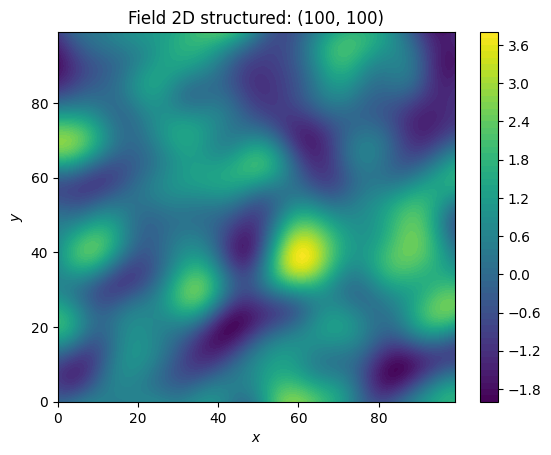

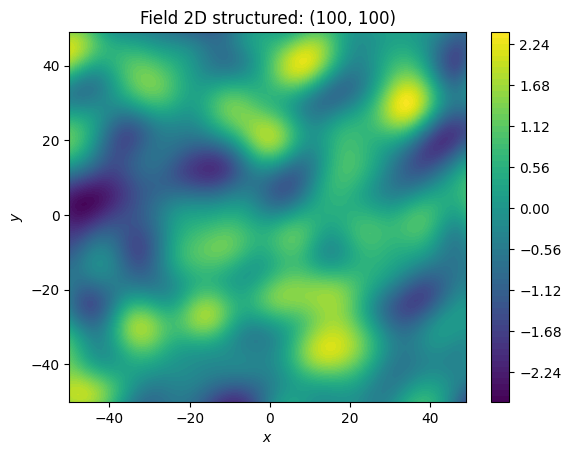

In [ ]:

# the variogram stays the same if shifting the corrdinates 
nx = ny = 100
x = y = range(nx)
model = gs.Gaussian(dim=2, var=1, len_scale=10)
srf = gs.SRF(model, seed = 1)
srf((x, y), mesh_type='structured')
srf.plot()
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print(bin_center, gamma, counts)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2
srf((x, y), mesh_type='structured')
srf.plot()
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print(bin_center, gamma, counts)


In [2]:
# a smaller length scale gives a rougher field
scale = 2
model = gs.Gaussian(dim=2, var=1, len_scale=scale, seed = 1)
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)
U = srf.structured([x, y],seed = 1)
plt.imshow(U)
plt.colorbar(label="Value")
plt.title(f"small length scale:l={scale}")
plt.show()

# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# fit the variogram with a stable model. (no nugget fitted)
fit_model = gs.Stable(dim=2)
fit_model.fit_variogram(bin_center, gamma, nugget=False)

ax = fit_model.plot(x_max=max(bin_center))
ax.scatter(bin_center, gamma)
plt.show()
# note under an isotropic field with variance 1, when the distance increases, covariance decreaes and  gamma increases and is close to 1. 

C:\Users\jiyue\miniconda3\envs\nilearn\lib\site-packages\gstools\covmodel\tools.py:163: AttributeWarning: The given optional argument 'seed' is unknown or has at least no defined standard value. Or you made a Typo... hehe.
  warnings.warn(


NameError: name 'plt' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def se_field_iso(nx=256, ny=256, ell=12.0, Lx=None, Ly=None, seed=0):
    """
    Isotropic squared-exponential field: C(h) ∝ exp(-||h||^2 / (2*ell^2))
    Periodic on [0,Lx]x[0,Ly]. Returns a (nx, ny) array with unit variance.
    """
    rng = np.random.default_rng(seed)
    if Lx is None: Lx = float(nx)
    if Ly is None: Ly = float(ny)

    kx = 2*np.pi*np.fft.fftfreq(nx, d=Lx/nx)
    ky = 2*np.pi*np.fft.fftfreq(ny, d=Ly/ny)
    KX, KY = np.meshgrid(kx, ky, indexing="ij")
    K2 = KX**2 + KY**2

    S = np.exp(-(ell**2) * K2)  # Gaussian spectrum
    S[0,0] = 0.0                # zero mean

    Z = rng.standard_normal((nx, ny)) + 1j*rng.standard_normal((nx, ny))
    f = np.fft.ifft2(np.sqrt(S) * Z).real
    return f / f.std(ddof=0)

def se_field_aniso(nx=256, ny=256, ell_x=24.0, ell_y=6.0, theta=np.deg2rad(30),
                   Lx=None, Ly=None, seed=1):
    """
    Stationary anisotropic squared-exponential field.
    'ell_x', 'ell_y' are correlation lengths along principal axes,
    rotated by angle 'theta' (radians, CCW from +x).
    """
    rng = np.random.default_rng(seed)
    if Lx is None: Lx = float(nx)
    if Ly is None: Ly = float(ny)

    kx = 2*np.pi*np.fft.fftfreq(nx, d=Lx/nx)
    ky = 2*np.pi*np.fft.fftfreq(ny, d=Ly/ny)
    KX, KY = np.meshgrid(kx, ky, indexing="ij")

    # rotate frequency coords into principal axes
    c, s = np.cos(theta), np.sin(theta)
    k1 =  c*KX + s*KY
    k2 = -s*KX + c*KY

    # anisotropic Gaussian spectrum (different length scales)
    S = np.exp(-(ell_x**2)*k1**2 - (ell_y**2)*k2**2)
    S[0,0] = 0.0

    Z = rng.standard_normal((nx, ny)) + 1j*rng.standard_normal((nx, ny))
    f = np.fft.ifft2(np.sqrt(S) * Z).real
    return f / f.std(ddof=0)

# --- generate both fields ---
U_iso  = se_field_iso(nx=256, ny=256, ell=14.0, seed=0)
U_anis = se_field_aniso(nx=256, ny=256, ell_x=28.0, ell_y=6.0, theta=np.deg2rad(35), seed=1)

# --- plot each as its own image (heatmap) ---
plt.figure(figsize=(6,5))
plt.imshow(U_iso, origin="lower", cmap="viridis")
plt.title("Isotropic Gaussian Field (SE covariance)")
plt.xlabel("x-index"); plt.ylabel("y-index")
plt.colorbar(label="value")
plt.show()

plt.figure(figsize=(6,5))
plt.imshow(U_anis, origin="lower", cmap="viridis")
plt.title("Stationary Anisotropic Gaussian Field")
plt.xlabel("x-index"); plt.ylabel("y-index")
plt.colorbar(label="value")
plt.show()


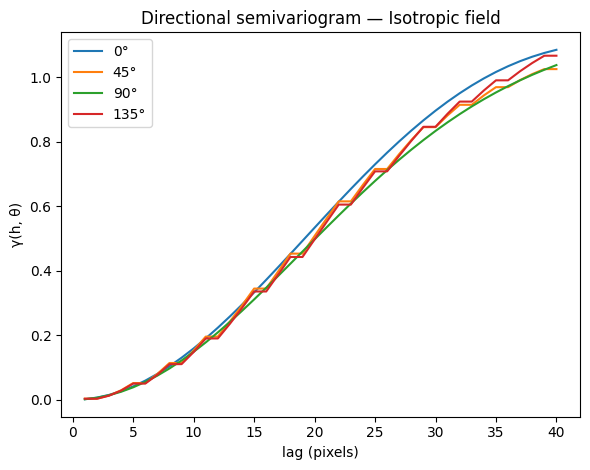

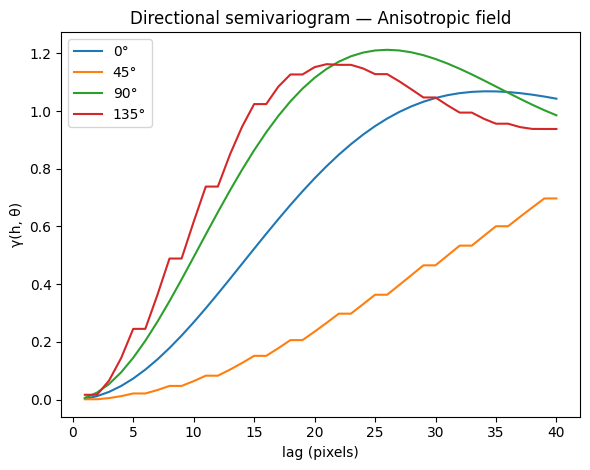

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def directional_semivariogram_grid(Z, directions_deg=(0, 45, 90, 135), max_lag_px=40):
    """
    Empirical directional semivariogram for a 2-D *gridded* field.

    Parameters
    ----------
    Z : (nx, ny) array
        2-D field.
    directions_deg : iterable of floats
        Directions (degrees, CCW from +x) along which to estimate the semivariogram.
    max_lag_px : int
        Maximum lag (in pixels) to evaluate; lags are 1..max_lag_px.

    Returns
    -------
    lags : (L,) array of ints
        Pixel lags.
    gamma_dir : dict
        Mapping angle -> (L,) semivariogram values at those lags.
        gamma(h, theta) = 0.5 * mean_{valid pairs} (Z(x) - Z(x + h_theta))^2
    """
    Z = np.asarray(Z)
    nx, ny = Z.shape
    lags = np.arange(1, max_lag_px + 1)
    gamma_dir = {}

    for theta in directions_deg:
        th = np.deg2rad(theta)
        # unit direction in pixels; per-lag offset is round(h*ux), round(h*uy)
        ux, uy = np.cos(th), np.sin(th)
        gvals = np.full_like(lags, np.nan, dtype=float)

        for i, h in enumerate(lags):
            dx = int(round(h * ux))
            dy = int(round(h * uy))
            if dx == 0 and dy == 0:
                continue

            # compute overlap slices for valid pairs
            if dx >= 0:
                xs = slice(0, nx - dx)
                xh = slice(dx, nx)
            else:
                xs = slice(-dx, nx)
                xh = slice(0, nx + dx)

            if dy >= 0:
                ys = slice(0, ny - dy)
                yh = slice(dy, ny)
            else:
                ys = slice(-dy, ny)
                yh = slice(0, ny + dy)

            A = Z[xs, ys]
            B = Z[xh, yh]
            if A.size == 0 or B.size == 0:
                continue
            gvals[i] = 0.5 * np.mean((A - B) ** 2)

        gamma_dir[theta] = gvals

    return lags, gamma_dir

# ---------- demo on isotropic vs anisotropic fields ----------
def se_field_iso(nx=256, ny=256, ell=14.0, seed=0):
    rng = np.random.default_rng(seed)
    kx = 2*np.pi*np.fft.fftfreq(nx)
    ky = 2*np.pi*np.fft.fftfreq(ny)
    KX, KY = np.meshgrid(kx, ky, indexing="ij")
    S = np.exp(- (ell**2) * (KX**2 + KY**2))
    S[0,0] = 0.0
    Z = rng.standard_normal((nx, ny)) + 1j*rng.standard_normal((nx, ny))
    f = np.fft.ifft2(np.sqrt(S) * Z).real
    return f / f.std(ddof=0)

def se_field_aniso(nx=256, ny=256, ell_x=28.0, ell_y=6.0, theta_deg=35, seed=1):
    rng = np.random.default_rng(seed)
    kx = 2*np.pi*np.fft.fftfreq(nx)
    ky = 2*np.pi*np.fft.fftfreq(ny)
    KX, KY = np.meshgrid(kx, ky, indexing="ij")
    th = np.deg2rad(theta_deg)
    c, s = np.cos(th), np.sin(th)
    k1 =  c*KX + s*KY
    k2 = -s*KX + c*KY
    S = np.exp(- (ell_x**2) * k1**2 - (ell_y**2) * k2**2)
    S[0,0] = 0.0
    Z = rng.standard_normal((nx, ny)) + 1j*rng.standard_normal((nx, ny))
    f = np.fft.ifft2(np.sqrt(S) * Z).real
    return f / f.std(ddof=0)

# build fields
U_iso  = se_field_iso()
U_anis = se_field_aniso()

# compute directional variograms
dirs = (0, 45, 90, 135)
lags, g_iso  = directional_semivariogram_grid(U_iso,  directions_deg=dirs, max_lag_px=40)
_,    g_anis = directional_semivariogram_grid(U_anis, directions_deg=dirs, max_lag_px=40)

# plot: isotropic (curves overlap) vs anisotropic (curves separate)
plt.figure(figsize=(6,4.8))
for th in dirs:
    plt.plot(lags, g_iso[th], label=f"{th}°")
plt.title("Directional semivariogram — Isotropic field")
plt.xlabel("lag (pixels)"); plt.ylabel("γ(h, θ)")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4.8))
for th in dirs:
    plt.plot(lags, g_anis[th], label=f"{th}°")
plt.title("Directional semivariogram — Anisotropic field")
plt.xlabel("lag (pixels)"); plt.ylabel("γ(h, θ)")
plt.legend(); plt.tight_layout(); plt.show()


In [2]:
import numpy as np
from scipy import signal, datasets, ndimage
rng = np.random.default_rng()
face = datasets.face(gray=True) - datasets.face(gray=True).mean()
face = ndimage.zoom(face[30:500, 400:950], 0.5)  # extract the face
# template.shape = (30,35)
template = np.copy(face[135:165, 140:175])  # right eye
template -= template.mean()
face = face + rng.standard_normal(face.shape) * 50  # add noise
print('face.shape:', face.shape, 'template.shape:', template.shape)
# mode='same' specifies that the output is the same size as the first input
# slides template over filter at every 2D shift, for each shift, sums the element-wise products of the overlap
# the output is a correlation surface 
corr = signal.correlate2d(face, template, boundary='symm', mode='same')
# find the location with the largest correlation 
y, x = np.unravel_index(np.argmax(corr), corr.shape)  # find the match

face.shape: (235, 275) template.shape: (30, 35)


C:\Users\jiyue\AppData\Local\Temp\ipykernel_14416\4054374508.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


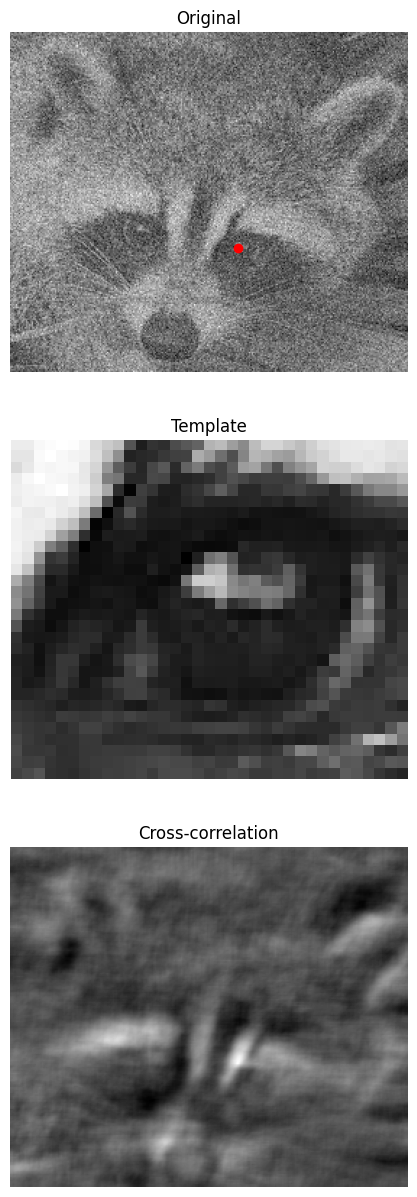

In [3]:
import matplotlib.pyplot as plt
fig, (ax_orig, ax_template, ax_corr) = plt.subplots(3, 1,
                                                    figsize=(6, 15))
ax_orig.imshow(face, cmap='gray')
ax_orig.set_title('Original')
ax_orig.set_axis_off()
ax_template.imshow(template, cmap='gray')
ax_template.set_title('Template')
ax_template.set_axis_off()
ax_corr.imshow(corr, cmap='gray')
ax_corr.set_title('Cross-correlation')
ax_corr.set_axis_off()
# highlights the match identified 
ax_orig.plot(x, y, 'ro')
fig.show()

In [ ]:
rng = np.random.default_rng(10)
print(rng)
print(rng.integers(0, 1e9))
print(rng.integers(0, 1e9))

In [ ]:
A = np.random.randn(5, 5) * 3   
M = 2.0

# clip to [-M, M]
np.clip(A, -M, M)

In [ ]:
rng = np.random.default_rng(42)          # optional seed for reproducibility
X = rng.integers(0, 3, size=(3, 3)) 
print(X)
Y =  rng.integers(0, 3, size=(3, 3)) 
print(Y)
# pad X with 0 by default, output shape (X.ux, X.uy)
cor1 = correlate2d(X, Y, boundary='fill', mode='same')
print(cor1)
print(cor1.shape)
# pad X with 0 by default, output shape: (X.ux +Y.ux-1, X.uy+Y.uy-1)
# the center value is the sum of element-wise product of X and Y
cor2 = correlate2d(X, Y, boundary='fill', mode='full')
print(cor2)
print(cor2.shape)

In [ ]:
import numpy as np
from scipy.signal import correlate2d, correlate
import tracemalloc

# compare correlate functions
nx = 200
X = np.random.normal(size = (nx,nx))
Y = np.random.normal(size = (nx,nx))

start = time.time()
tracemalloc.start()
# when both input fields are large, fft method is much faster 
# fft method takes 0.02 seconds for 200*200, direct method takes 115 seconds
out1 = correlate(X, Y, mode = 'full', method = 'auto')
# Get current and peak memory usage
current, peak = tracemalloc.get_traced_memory()
#print(f"Current memory usage: {current / 10**6:.2f} MB")
print(f"Peak memory usage: {peak / 10**6:.2f} MB")
tracemalloc.stop()
end = time.time()
print(f"Runtime: {end - start:.4f} seconds")

start = time.time()
tracemalloc.start()
# takes 14 seconds for 200*200
# this uses the direct method and gives the same result as correlate with direct method (exactly same) and fft method (diff less than 10^-12)
out2 = correlate2d(X, Y, mode = 'full')
# Get current and peak memory usage
current, peak = tracemalloc.get_traced_memory()
print(f"Peak memory usage: {peak / 10**6:.2f} MB")
tracemalloc.stop()
end = time.time()
print(f"Runtime: {end - start:.4f} seconds")
print(np.all(out1 == out2))
print(out1)
print(out2)
np.max(np.abs(out1-out2))